In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
Data = pd.read_csv("Customer_Transactions.csv")
print(Data)


      customer_id  age  gender    country  annual_income  spending_score  \
0               1   37    Male    Germany          85886              14   
1               2   40    Male      India          41041               4   
2               3   69  Female  Australia         143869              59   
3               4   30    Male         UK          87261              45   
4               5   69  Female         UK         110678              40   
...           ...  ...     ...        ...            ...             ...   
9995         9996   39  Female     France          45002              39   
9996         9997   44    Male        USA          95367              86   
9997         9998   25  Female        USA          73884              33   
9998         9999   19  Female        USA          80849              85   
9999        10000   66    Male      India          75854              60   

      num_purchases  avg_purchase_value  membership_years  \
0                18       

In [8]:
# Step 1: Select the required numerical features (Annual Income and Spending Score)
# Extract the first two selected features from the customer transaction dataset
# Display the shape of the selected dataset

X = Data.iloc[:, :2]  
print("Dataset shape:", X.shape)

Dataset shape: (10000, 2)


In [13]:
# Step 3: Import StandardScaler from sklearn
# Standardize the selected features to bring them onto the same scale
# Fit and transform the data using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [16]:
# Initialize an empty list to store inertia values
# Apply K-Means clustering for different values of K (1 to 10)
# Calculate and store the inertia value for each cluster

inertia = []

for k in range(1, 11):

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)


In [15]:
print(Data.head())
print(Data.columns)
print(Data.shape)

   customer_id  age  gender    country  annual_income  spending_score  \
0            1   37    Male    Germany          85886              14   
1            2   40    Male      India          41041               4   
2            3   69  Female  Australia         143869              59   
3            4   30    Male         UK          87261              45   
4            5   69  Female         UK         110678              40   

   num_purchases  avg_purchase_value  membership_years  \
0             18               41.20                 6   
1             10               31.73                 4   
2             39               65.96                12   
3             34               51.87                12   
4             38               59.64                13   

   website_visits_per_month  cart_abandon_rate  churned  \
0                        20               0.95        0   
1                        29               0.21        0   
2                        26        

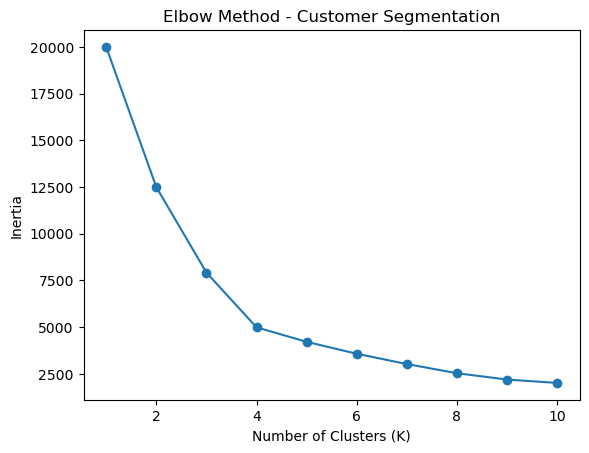

In [17]:
#Plot the Elbow Method graph using the calculated inertia values
# Display the number of clusters on the X-axis and inertia on the Y-axis
# Use the graph to identify the optimal number of clusters
plt.plot(range(1, 11), inertia, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method - Customer Segmentation")

plt.show()

In [18]:
 #Apply the K-Means clustering algorithm with 3 clusters
# Set random_state for reproducible results
# Fit the model and predict the cluster labels for each customer
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_scaled)

print("Cluster labels:")
print(clusters)

Cluster labels:
[0 0 1 ... 2 2 2]


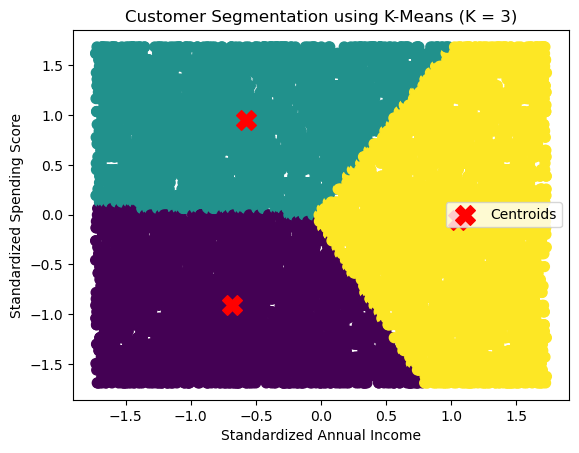

In [19]:
#Visualize the customer clusters using a scatter plot
# Represent different clusters using different colours
# Plot the cluster centroids using red X markers
# Add axis labels, title and legend to the graph

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200,
    color='red',
    label='Centroids'
)

plt.xlabel("Standardized Annual Income")
plt.ylabel("Standardized Spending Score")

plt.title("Customer Segmentation using K-Means (K = 3)")

plt.legend()
plt.show()

In [20]:
#Add the predicted cluster labels to the original dataset
# Display customer ID, annual income, spending score and assigned cluster
# Analyze the average annual income and spending score of each cluster

Data['Cluster'] = clusters

print(Data[['customer_id', 'annual_income',
            'spending_score', 'Cluster']].head(10))

   customer_id  annual_income  spending_score  Cluster
0            1          85886              14        0
1            2          41041               4        0
2            3         143869              59        1
3            4          87261              45        0
4            5         110678              40        1
5            6          90330               2        0
6            7          27302              51        0
7            8          39171              83        0
8            9          54766              27        1
9           10          47550              46        0
